## **6CS030 Big Data Portfolio - Code Appendix**

### **Predicting Mental Health Treatment Needs Using Behavioral and Occupational Data**

**Name:** Luniva Shrestha  
**Student Number:** 2433240  
**Group Name:** L6CG23  
**Tutor:** Sushil Timilsina

### **Introduction:**
This project builds a binary classification model to predict whether an individual requires mental health treatment (“Yes/No”) based on behavioral, psychological, occupational, and demographic features. Machine learning models (Random Forest and XGBoost) are used to identify key predictive patterns and evaluate which factors most strongly influence treatment likelihood.


### **Dataset Description:**
The dataset contains 292,364 survey responses with 17 features, mostly categorical, covering behavior, psychological history, and demographics, with treatment as the target variable indicating whether a person sought mental health support.

### **Source:**
https://zenodo.org/records/11203863

### **1: Importing necessary Libraries**

In [ ]:
# Standard libraries
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib # For model saving

warnings.filterwarnings('ignore')  # Suppress warnings

# Machine Learning tools
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, roc_curve, auc
)

# Spark setup
from pyspark.sql import SparkSession
from pyspark.sql.functions import col

print("Libraries imported successfully.")

Libraries imported successfully.


### **2: Install and Initialize Spark**

#### **2.1: System Setup and Spark Initialization**

In [ ]:
# Install required Spark libraries
!pip install pyspark findspark

#### **2.2: Import and Initialize Spark**

In [ ]:
import findspark
findspark.init()  # Initialize Spark

from pyspark.sql import SparkSession

# Create Spark session
spark = SparkSession.builder.appName("MentalHealthPrediction").getOrCreate()

print("SparkSession initialized.")

SparkSession initialized.


### **3: Mount and Load Dataset**

#### **3.1: Mount Google Drive**

In [ ]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### **3.2: Load Dataset**

In [ ]:
# Load dataset into Spark DataFrame
spark_df = spark.read.csv('/content/drive/MyDrive/BigData/Dataset.csv', header=True, inferSchema=True)

print("Dataset loaded successfully.")

Dataset loaded successfully.


### **4: Dataset Information**

#### **4.1: DataFrame Schema**

In [ ]:
# Display DataFrame schema
print("Spark DataFrame Schema:")
spark_df.printSchema()

Spark DataFrame Schema:
root
 |-- Timestamp: string (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Occupation: string (nullable = true)
 |-- self_employed: string (nullable = true)
 |-- family_history: string (nullable = true)
 |-- treatment: string (nullable = true)
 |-- Days_Indoors: string (nullable = true)
 |-- Growing_Stress: string (nullable = true)
 |-- Changes_Habits: string (nullable = true)
 |-- Mental_Health_History: string (nullable = true)
 |-- Mood_Swings: string (nullable = true)
 |-- Coping_Struggles: string (nullable = true)
 |-- Work_Interest: string (nullable = true)
 |-- Social_Weakness: string (nullable = true)
 |-- mental_health_interview: string (nullable = true)
 |-- care_options: string (nullable = true)



#### **4.2: First 5 rows**

In [ ]:
# Display first 5 rows of the DataFrame
print("First 5 rows of Spark DataFrame:")
spark_df.show(5)

First 5 rows of Spark DataFrame:
+---------------+------+-------------+----------+-------------+--------------+---------+------------+--------------+--------------+---------------------+-----------+----------------+-------------+---------------+-----------------------+------------+
|      Timestamp|Gender|      Country|Occupation|self_employed|family_history|treatment|Days_Indoors|Growing_Stress|Changes_Habits|Mental_Health_History|Mood_Swings|Coping_Struggles|Work_Interest|Social_Weakness|mental_health_interview|care_options|
+---------------+------+-------------+----------+-------------+--------------+---------+------------+--------------+--------------+---------------------+-----------+----------------+-------------+---------------+-----------------------+------------+
|8/27/2014 11:29|Female|United States| Corporate|         NULL|            No|      Yes|   1-14 days|           Yes|            No|                  Yes|     Medium|              No|           No|            Yes|     

#### **4.3: Show Initial Shape**

In [ ]:
# Print number of rows and columns
print(f"Dataset shape: ({spark_df.count()}, {len(spark_df.columns)})")

Dataset shape: (292364, 17)


### **5: Data Cleaning and Preprocessing**

#### **5.1: Checking Missing Values**

In [ ]:
# Calculate missing values per column
missing_counts_dict = {}

for column_name in spark_df.columns:
    null_count = spark_df.filter(col(column_name).isNull()).count()

    if null_count > 0:
        missing_counts_dict[column_name] = null_count

# Convert to pandas Series for display
if missing_counts_dict:
    missing_series = pd.Series(missing_counts_dict)
    print("Missing values:\n")
    display(missing_series)
else:
    print("No missing values found")

Missing values:



,0
self_employed,5202


#### **5.2: Handling Missing Values**

In [ ]:
# Fill missing values in specific column
spark_df = spark_df.fillna({"self_employed": "Unknown"})

# Confirm changes
print("Missing values filled with 'Unknown'")
print(f"New shape: ({spark_df.count()}, {len(spark_df.columns)})")

Missing values filled with 'Unknown'
New shape: (292364, 17)


**Explanation:** Missing values in 'self_employed' were filled with 'Unknown' to prevent data loss and ensure model compatibility.

#### **5.3: Dropping Unnecessary Column (Timestamp)**

In [ ]:
# Drop timestamp column if it exists
if 'Timestamp' in spark_df.columns:
    spark_df = spark_df.drop('Timestamp')
    print("Timestamp column dropped")
else:
    print("Timestamp column not found")

Timestamp column dropped


**Explanation:** The 'Timestamp' column was dropped as it has no predictive value.

#### **5.4: Removing Duplicate Records**

In [ ]:
# Check and remove duplicate rows
initial_row_count = spark_df.count()
spark_df_distinct = spark_df.dropDuplicates()

duplicates = initial_row_count - spark_df_distinct.count()
print("Number of duplicate rows found:", duplicates)

if duplicates > 0:
    spark_df = spark_df_distinct
    print("Duplicates removed successfully")
    print(f"New shape: ({spark_df.count()}, {len(spark_df.columns)})")
else:
    print("No duplicates found")

Number of duplicate rows found: 194641
Duplicates removed successfully
New shape: (97723, 16)


**Explanation:** 194,641 duplicate rows were removed to prevent model bias and overfitting.

#### **5.5: Conversion from Spark to Pandas DataFrame**

In [ ]:
# Convert Spark DataFrame to Pandas DataFrame
df = spark_df.toPandas()

print("Spark converted to Pandas")

Spark converted to Pandas


**Explanation:** The Spark DataFrame was converted to a Pandas DataFrame to use Python libraries like Pandas, Matplotlib, Seaborn, and Scikit-learn for easier data analysis, visualization, and machine learning.

#### **5.6: Basic Statistical Summary of Key Features**

In [ ]:
# Key feature distributions
key_cols = ['Growing_Stress', 'Days_Indoors', 'Mood_Swings', 'family_history',
            'Gender', 'Occupation', 'treatment']

# Show percentage distribution
for col in key_cols:
    print(f"\n{col} distribution (%):")
    display(df[col].value_counts(normalize=True).round(2) * 100)


Growing_Stress distribution (%):


,proportion
Growing_Stress,
Yes,34.0
Maybe,34.0
No,32.0



Days_Indoors distribution (%):


,proportion
Days_Indoors,
1-14 days,22.0
31-60 days,21.0
Go out Every day,20.0
More than 2 months,19.0
15-30 days,19.0



Mood_Swings distribution (%):


,proportion
Mood_Swings,
Medium,35.0
Low,34.0
High,31.0


... (4 outputs left out)


Occupation distribution (%):


,proportion
Occupation,
Housewife,23.0
Student,21.0
Corporate,21.0
Others,18.0
Business,17.0



treatment distribution (%):


,proportion
treatment,
No,52.0
Yes,48.0


### **6: Exploratory Data Analysis (EDA)**

#### **6.1: Univariate Analysis**

**6.1.1: Distribution of Growing Stress**

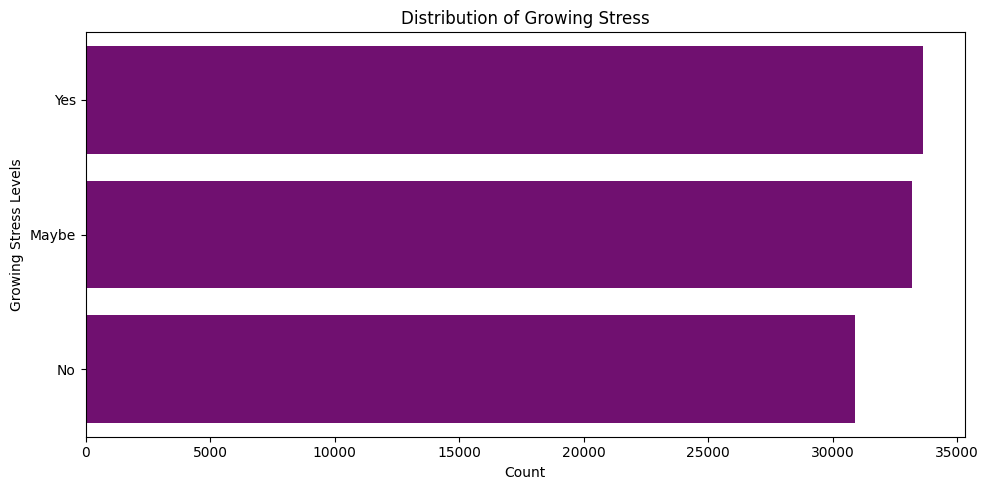

In [ ]:
# Order categories by frequency
order = df['Growing_Stress'].value_counts().index

# Plot distribution
plt.figure(figsize=(10, 5))
sns.countplot(y='Growing_Stress', data=df, order=order, color='purple')
plt.title('Distribution of Growing Stress')
plt.xlabel('Count')
plt.ylabel('Growing Stress Levels')
plt.tight_layout()
plt.show()

**Observations on Growing Stress:**

The chart shows that most respondents reported experiencing growing stress, with “Yes” having the highest count, followed closely by “Maybe.” The “No” category has the lowest count, indicating that stress is common among the respondents.

**6.1.2: Distribution of Days Indoors**

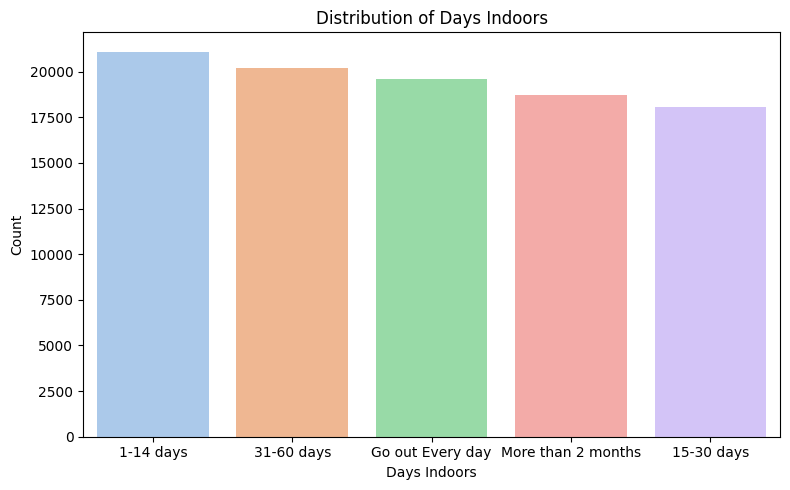

In [ ]:
# Get value counts
counts = df['Days_Indoors'].value_counts()

# Plot distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='Days_Indoors', data=df, order=counts.index, palette='pastel')
plt.title('Distribution of Days Indoors')
plt.xlabel('Days Indoors')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

**Observations on Days Indoors:**

The chart indicates that most respondents stayed indoors for 1–14 days, while the fewest respondents reported staying indoors for 15–30 days. Overall, the distribution across categories is relatively balanced, showing varied indoor stay durations among respondents.

**6.1.3: Distribution of Mood Swings**

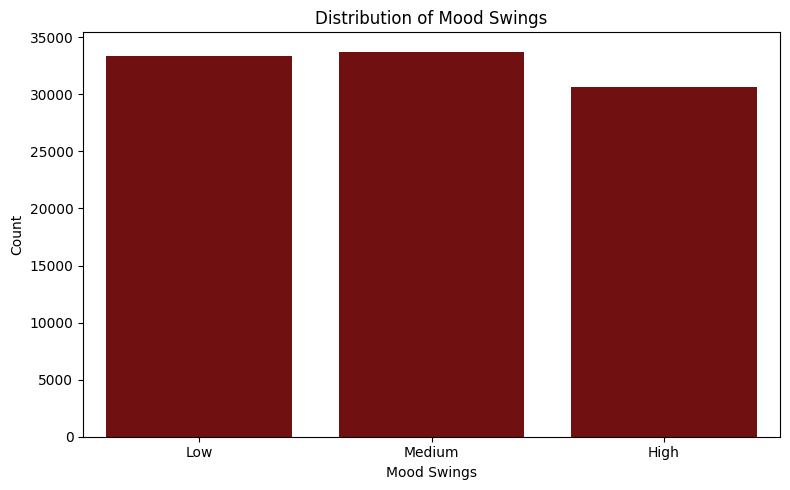

In [ ]:
# Plot distribution of Mood Swings
plt.figure(figsize=(8,5))
sns.countplot(x='Mood_Swings', data=df, color='maroon')
plt.title('Distribution of Mood Swings')
plt.xlabel('Mood Swings')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

**Observations on Mood Swings:**

The chart shows that medium mood swings are reported the most, followed closely by low mood swings, while high mood swings have the lowest count. This suggests that most respondents experience mild to moderate mood fluctuations rather than severe ones.

**6.1.4: Distribution of Occupation**

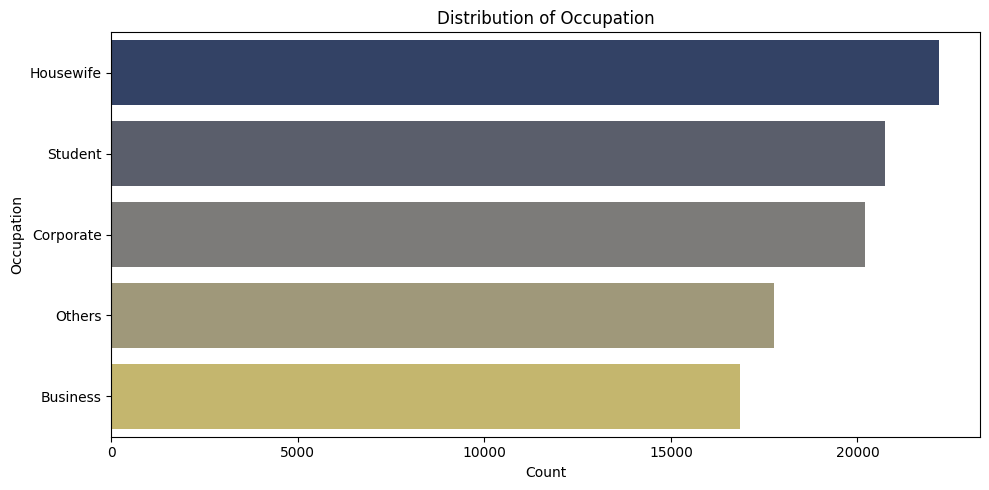

In [ ]:
# Plot distribution of Occupation
plt.figure(figsize=(10, 5))
sns.countplot(y='Occupation', data=df, palette='cividis', order=df['Occupation'].value_counts().index)
plt.title('Distribution of Occupation')
plt.xlabel('Count')
plt.ylabel('Occupation')
plt.tight_layout()
plt.show()

**Observations on Occupation:**

Housewives form the largest group, followed by Students and Corporate professionals. Business has the smallest share. The chart shows a clear dominance of homemakers in the dataset.

#### **6.2: Behavioral Analysis**

**6.2.1: Growing Stress vs Days Indoors**

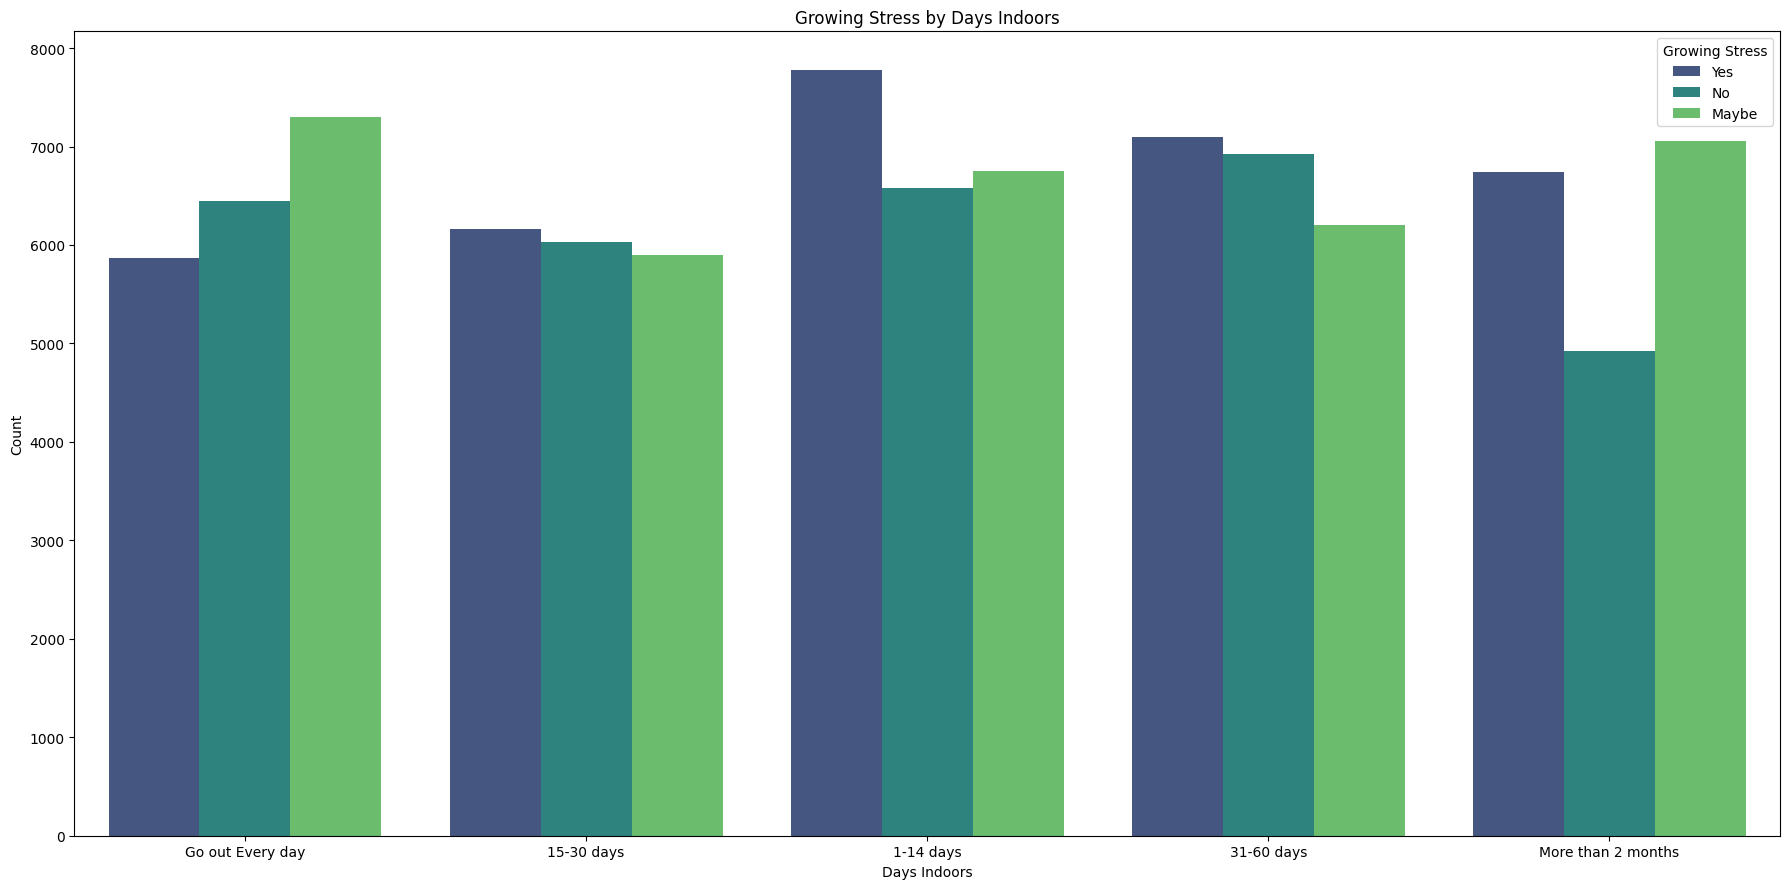

In [ ]:
# Plot Growing Stress by Days Indoors
plt.figure(figsize=(18,9))
sns.countplot(x='Days_Indoors', hue='Growing_Stress', data=df, palette='viridis')
plt.title('Growing Stress by Days Indoors')
plt.xlabel('Days Indoors')
plt.ylabel('Count')
plt.legend(title='Growing Stress')
plt.tight_layout()
plt.show()

**Explanation: Growing Stress vs Days Indoors:**

People who go out every day report the lowest "Yes" for growing stress and the highest "Maybe". As days spent indoors increase, the "Yes" responses for growing stress become more prominent, especially in the 1-14 days and 31-60 days categories. Those staying indoors for more than 2 months show high "Yes" and "Maybe", with the lowest "No".

Overall, longer time indoors is associated with higher reported growing stress.

**6.2.2: Mood Swings vs Treatment (%)**

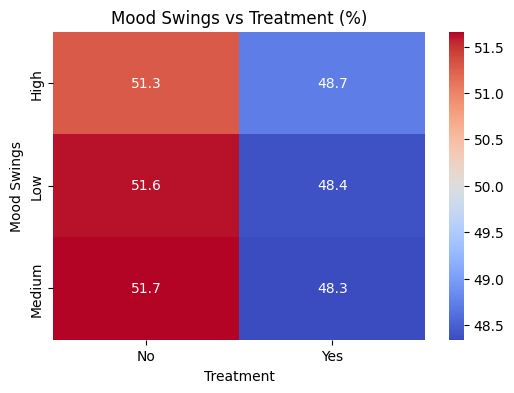

In [ ]:
# Create cross-tab for Mood Swings vs Treatment
ct = pd.crosstab(df['Mood_Swings'], df['treatment'], normalize='index') * 100

# Plot heatmap
plt.figure(figsize=(6,4))
sns.heatmap(ct, annot=True, cmap='coolwarm', fmt='.1f')
plt.title('Mood Swings vs Treatment (%)')
plt.xlabel('Treatment')
plt.ylabel('Mood Swings')
plt.show()

**Explanation: Mood Swings vs Treatment (%):**

People not receiving treatment consistently show a slightly higher proportion of mood swings (across High, Medium, and Low levels) compared to those receiving treatment.

The difference is small but uniform — treatment is associated with modestly lower mood swing reports regardless of intensity.

**6.2.3: Changes in Habits vs Treatment**

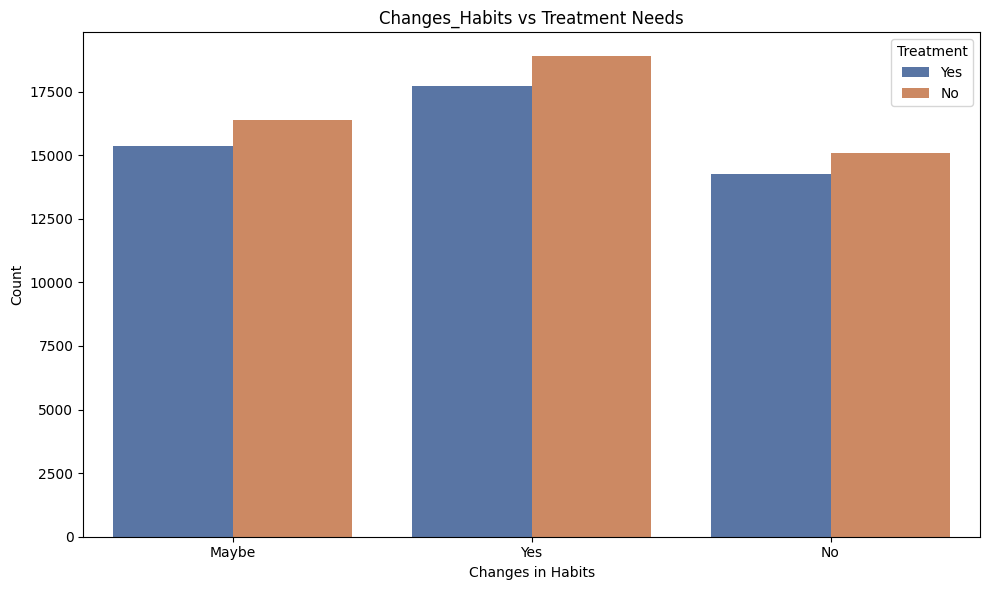

In [ ]:
# Plot Changes_Habits vs Treatment
plt.figure(figsize=(10, 6))
sns.countplot(x='Changes_Habits', hue='treatment', data=df, palette='deep')
plt.title('Changes_Habits vs Treatment Needs')
plt.xlabel('Changes in Habits')
plt.ylabel('Count')
plt.legend(title='Treatment')
plt.tight_layout()
plt.show()

**Explanation: Changes_Habits vs Treatment:**

People reporting Yes to changes in habits have the highest counts overall.

Across all categories (Yes, Maybe, No), those who do not need treatment consistently show slightly higher numbers than those who do. The pattern suggests that changes in habits are common, but treatment needs remain relatively balanced.

**6.2.4: Mental Health History vs Treatment (%)**

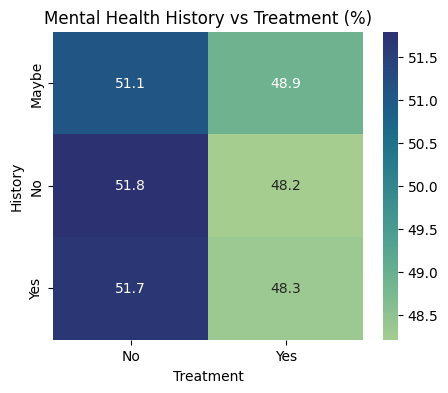

In [ ]:
# Cross-tab for Mental Health History vs Treatment
ct = pd.crosstab(df['Mental_Health_History'], df['treatment'], normalize='index') * 100

# Plot heatmap
plt.figure(figsize=(5,4))
sns.heatmap(ct, annot=True, cmap='crest', fmt='.1f')
plt.title('Mental Health History vs Treatment (%)')
plt.xlabel('Treatment')
plt.ylabel('History')
plt.show()

**Explanation: Impact of Mental Health History:**

People without treatment consistently represent a slightly higher proportion across all mental health history categories (Yes, No, and Maybe) compared to those receiving treatment. The difference is small but uniform, indicating that treatment is associated with modestly lower reported mental health history prevalence.

**6.2.5: Family History vs Treatment (%)**

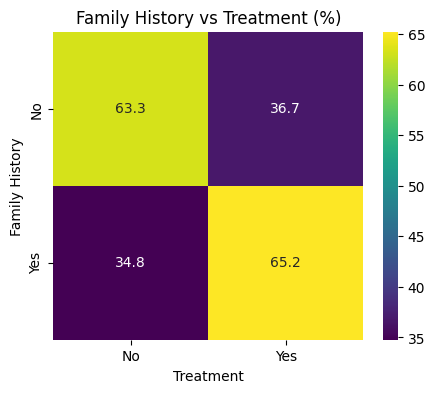

In [ ]:
# Cross-tab for Family History vs Treatment
ct = pd.crosstab(df['family_history'], df['treatment'], normalize='index') * 100

# Plot heatmap
plt.figure(figsize=(5,4))
sns.heatmap(ct, annot=True, cmap='viridis', fmt='.1f')
plt.title('Family History vs Treatment (%)')
plt.xlabel('Treatment')
plt.ylabel('Family History')
plt.show()

**Insight: Family History and Mental Health Support:**

There is a strong association between family history and treatment:


*   People with family history are far more likely to be receiving treatment (65.2%).
*   People without family history are mostly not receiving treatment (63.3%).

Family history appears to be a significant factor linked to higher treatment uptake.

**6.2.6: Social Weakness vs Treatment (%)**

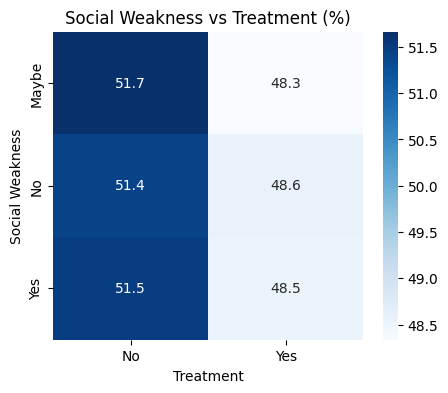

In [ ]:
# Cross-tab for Social Weakness vs Treatment
ct = pd.crosstab(df['Social_Weakness'], df['treatment'], normalize='index') * 100

# Plot heatmap
plt.figure(figsize=(5,4))
sns.heatmap(ct, annot=True, cmap='Blues', fmt='.1f')
plt.title('Social Weakness vs Treatment (%)')
plt.xlabel('Treatment')
plt.ylabel('Social Weakness')
plt.show()

**Analysis: Social Weakness and Support Structures:**

People not receiving treatment consistently show a slightly higher proportion across all levels of social weakness (Yes, No, and Maybe) compared to those who are receiving treatment.
The difference is small and uniform.

#### **6.3: Occupational and Gender-Based Analysis**

**6.3.1: Treatment Needs by Occupation (%)**

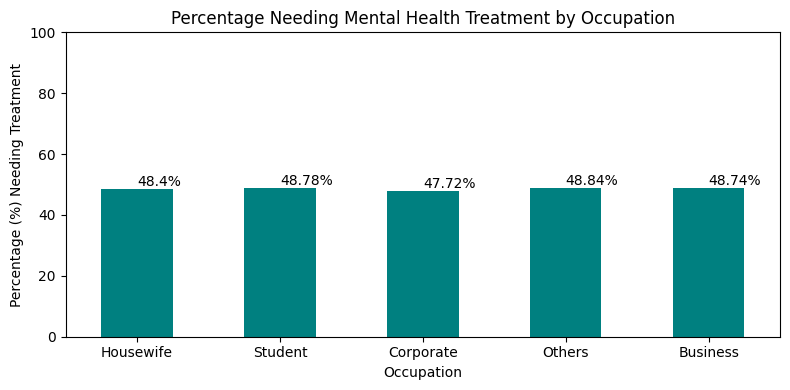

In [ ]:
# Calculate occupation totals and treatment counts
occ_total = df['Occupation'].value_counts()
occ_yes = df[df['treatment'] == 'Yes']['Occupation'].value_counts()
percentage_occ_yes = (occ_yes / occ_total * 100).round(2)

# Plot percentage needing treatment by occupation
plt.figure(figsize=(8,4))
percentage_occ_yes.plot(kind='bar', color='teal')
plt.title('Percentage Needing Mental Health Treatment by Occupation')
plt.xlabel('Occupation')
plt.ylabel('Percentage (%) Needing Treatment')
plt.ylim(0, 100)
plt.xticks(rotation=0, ha='center')

# Add value labels
for i, v in enumerate(percentage_occ_yes):
    plt.text(i, v + 1, f"{v}%")

plt.tight_layout()
plt.show()

**Insight: Occupation and Mental Health:**

Treatment need is remarkably consistent across all occupations, hovering around 47–49%. Housewives and Others show slightly higher percentages, while Corporate shows the lowest. Occupation appears to have minimal impact on treatment needs.

**6.3.2: Treatment Needs by Gender (%)**

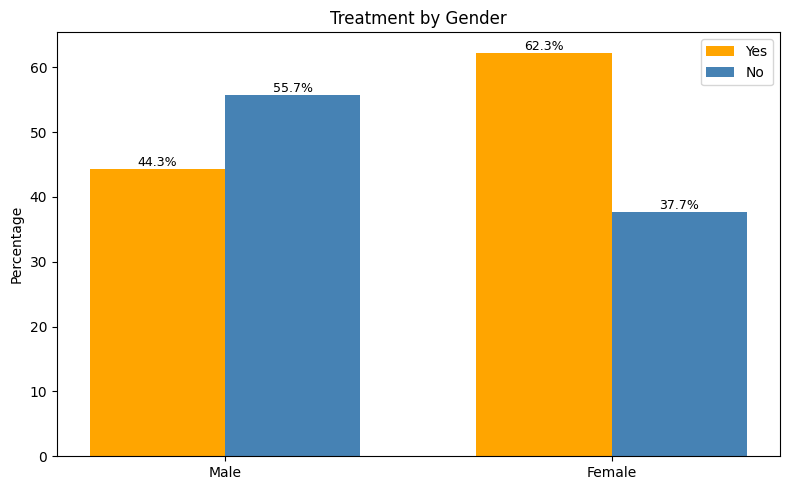

In [ ]:
# Calculate gender totals and treatment counts
gender_total = df['Gender'].value_counts()
gender_yes = df[df['treatment'] == 'Yes']['Gender'].value_counts()
gender_no = df[df['treatment'] == 'No']['Gender'].value_counts()

percentage_yes = (gender_yes / gender_total * 100).round(2)
percentage_no = (gender_no / gender_total * 100).round(2)

x = ['Male', 'Female']
width = 0.35

plt.figure(figsize=(8,5))

# Yes bars
bars1 = plt.bar([i - width/2 for i in range(len(x))],
                percentage_yes.reindex(x, fill_value=0),
                width=width, label='Yes', color='orange')

# No bars
bars2 = plt.bar([i + width/2 for i in range(len(x))],
                percentage_no.reindex(x, fill_value=0),
                width=width, label='No', color='steelblue')

# Add labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2,
                 height,
                 f'{height:.1f}%',
                 ha='center', va='bottom', fontsize=9)

plt.title('Treatment by Gender')
plt.ylabel('Percentage')
plt.xticks(range(len(x)), x)
plt.legend()

plt.tight_layout()
plt.show()

**Insight: Gender and Treatment Needs:**

There is a notable gender difference. Females are significantly more likely to receive treatment (62.3%) compared to males (44.3%). This suggests gender plays a stronger role in mental health treatment-seeking behavior.

**6.3.3: Self-Employed Status vs Treatment (%)**

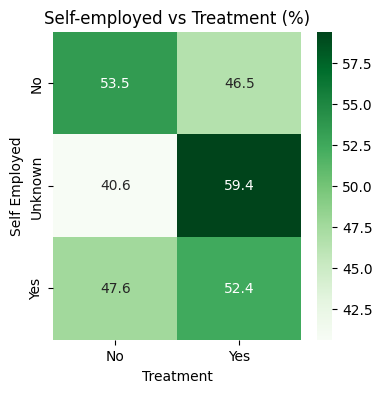

In [ ]:
# Cross-tab for Self-employed vs Treatment
ct = pd.crosstab(df['self_employed'], df['treatment'], normalize='index') * 100

# Plot heatmap
plt.figure(figsize=(4,4))
sns.heatmap(ct, annot=True, cmap='Greens', fmt='.1f')
plt.title('Self-employed vs Treatment (%)')
plt.xlabel('Treatment')
plt.ylabel('Self Employed')
plt.show()

**Insight: Self-Employment and Mental Health:**

Self-employed individuals show a slightly higher likelihood of receiving treatment (52.4%). Interestingly, the "Unknown" self-employment category has the highest treatment rate (59.4%), while those not self-employed lean toward no treatment.

#### **6.4: Class Distribution Analysis**

**6.4.1: Treatment Class Imbalance Check**

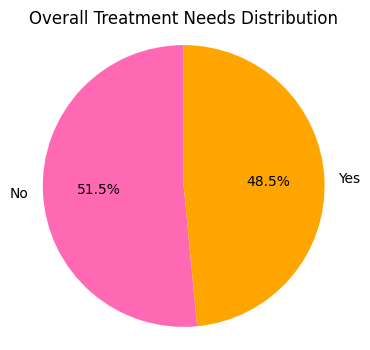

In [ ]:
# Plot treatment distribution
plt.figure(figsize=(4,4))
treatment_counts = df['treatment'].value_counts()
plt.pie(treatment_counts, labels=treatment_counts.index, autopct='%1.1f%%',
        colors=['hotpink', 'orange'], startangle=90)
plt.title('Overall Treatment Needs Distribution')
plt.axis('equal')
plt.show()

**Observations on Treatment Needs Distribution:**

Overall, 48.5% of the population needs mental health treatment, while 51.5% do not. The distribution is nearly balanced, indicating a substantial portion of people may benefit from support.

### **7: Data Preparation for Modeling**

#### **7.1: Train-Test Split**

In [ ]:
# Split features and target
X = df.drop('treatment', axis=1)
y = df['treatment']

# Train-test split (on raw labels first)
X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Encode target variable using only training data
le_target = LabelEncoder()
y_train = le_target.fit_transform(y_train_raw.astype(str))
y_test = le_target.transform(y_test_raw.astype(str))

# Confirm split
print("Train-test split completed")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Train-test split completed
X_train shape: (78178, 15)
X_test shape: (19545, 15)
y_train shape: (78178,)
y_test shape: (19545,)


#### **7.2: Encoding Categorical Variables**

In [ ]:
# List categorical columns
categorical_cols = X.columns

# Preprocessing pipeline for categorical encoding
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ), categorical_cols)
    ]
)

**Understanding the Modeling Pipeline and Preprocessing**

*   **ColumnTransformer with OrdinalEncoder:** Encodes categorical data using OrdinalEncoder, handling unseen values.
*   **Pipeline:** Combines preprocessing and model for consistency.
*   **No Data Leakage:** Ensures reliability by fitting only on training data.

### **8: Model Development**

#### **8.1: Random Forest Classifier**

In [ ]:
# Build Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    ))
])

# Define parameter distribution
rf_param_dist = {
    'model__n_estimators': [100, 200, 300, 400, 500],
    'model__max_depth': [None, 5, 10, 12, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2']
}

# Randomized Search
rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=20,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train model and measure time
start_time = time.time()
rf_random_search.fit(X_train, y_train)
rf_train_time = time.time() - start_time

# Best model
best_rf = rf_random_search.best_estimator_
# Predictions
rf_pred = best_rf.predict(X_test)

# Evaluation
print("Best Parameters:", rf_random_search.best_params_)
print(f"Random Forest Training Time: {rf_train_time:.2f} seconds")
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 10}
Random Forest Training Time: 574.37 seconds
Random Forest Accuracy: 0.7714504988488105
              precision    recall  f1-score   support

           0       0.81      0.73      0.77     10070
           1       0.74      0.81      0.78      9475

    accuracy                           0.77     19545
   macro avg       0.77      0.77      0.77     19545
weighted avg       0.77      0.77      0.77     19545



**Interpretation of Random Forest Metrics**
*   **Accuracy (~77.14%):** Good overall performance.
*   **Precision (0.77):** 75% correct when predicting treatment.
*   **Recall (0.77):** Identifies most people who need treatment.
*   **F1-Score (0.77):** Balanced performance.

#### **8.2: XGBoost Classifier with Hyperparameter Tuning (RandomizedSearchCV)**

In [ ]:
# Class balance handling
ratio = np.sum(y_train == 0) / np.sum(y_train == 1)

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        scale_pos_weight=ratio
    ))
])

# Hyperparameter Tuning
xgb_param_dist = {
    'model__n_estimators': [200, 300, 400, 600],
    'model__learning_rate': [0.01, 0.02, 0.05, 0.1],
    'model__max_depth': [3, 4, 5, 6],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'model__gamma': [0, 0.1, 0.2, 0.3, 0.5],
    'model__min_child_weight': [1, 3, 5, 7]
}

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_dist,
    n_iter=50,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

start_time = time.time()
xgb_random_search.fit(X_train, y_train)
xgb_train_time = time.time() - start_time

best_xgb = xgb_random_search.best_estimator_
xgb_pred = best_xgb.predict(X_test)

print("Best Parameters:", xgb_random_search.best_params_)
print(f"Training Time: {xgb_train_time:.2f}s")
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print(classification_report(y_test, xgb_pred))

Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best Parameters: {'model__subsample': 1.0, 'model__n_estimators': 400, 'model__min_child_weight': 7, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__gamma': 0.5, 'model__colsample_bytree': 0.7}
Training Time: 353.13s
Accuracy: 0.8141212586339217
              precision    recall  f1-score   support

           0       0.85      0.77      0.81     10070
           1       0.78      0.86      0.82      9475

    accuracy                           0.81     19545
   macro avg       0.82      0.82      0.81     19545
weighted avg       0.82      0.81      0.81     19545



**Interpretation of XGBoost Metrics**
*   **Accuracy (~81.14%):** Better overall performance than Random Forest.
*   **Precision (0.82):** Reasonably accurate when predicting treatment.
*   **Recall (0.81):** Strong improvement in identifying people who need help.
*   **F1-Score (0.81):** Best balance between precision and recall.

### **9: Model Evaluation and Comparison**

#### **9.1: Performance Comparison Table**

In [ ]:
# Calculate model accuracies and other metrics
rf_acc = accuracy_score(y_test, rf_pred)
xgb_acc = accuracy_score(y_test, xgb_pred)
rf_precision = precision_score(y_test, rf_pred, average='weighted')
xgb_precision = precision_score(y_test, xgb_pred, average='weighted')
rf_recall = recall_score(y_test, rf_pred, average='weighted')
xgb_recall = recall_score(y_test, xgb_pred, average='weighted')
rf_f1 = f1_score(y_test, rf_pred, average='weighted')
xgb_f1 = f1_score(y_test, xgb_pred, average='weighted')

# Compare model performance comprehensively
comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'Training Time (s)'
    ],
    'Random Forest': [
        rf_acc,
        rf_precision,
        rf_recall,
        rf_f1,
        rf_train_time
    ],
    'XGBoost': [
        xgb_acc,
        xgb_precision,
        xgb_recall,
        xgb_f1,
        xgb_train_time
    ]
})

# Display comparison table
print("Comprehensive Model Performance and Training Comparison:")
display(comparison)

Comprehensive Model Performance and Training Comparison:


,Metric,Random Forest,XGBoost
0,Accuracy,0.771450,0.814121
1,Precision,0.774750,0.817649
2,Recall,0.771450,0.814121
3,F1-Score,0.771243,0.813958
4,Training Time (s),574.368052,353.133279


#### **9.2: Confusion Matrix Analysis**

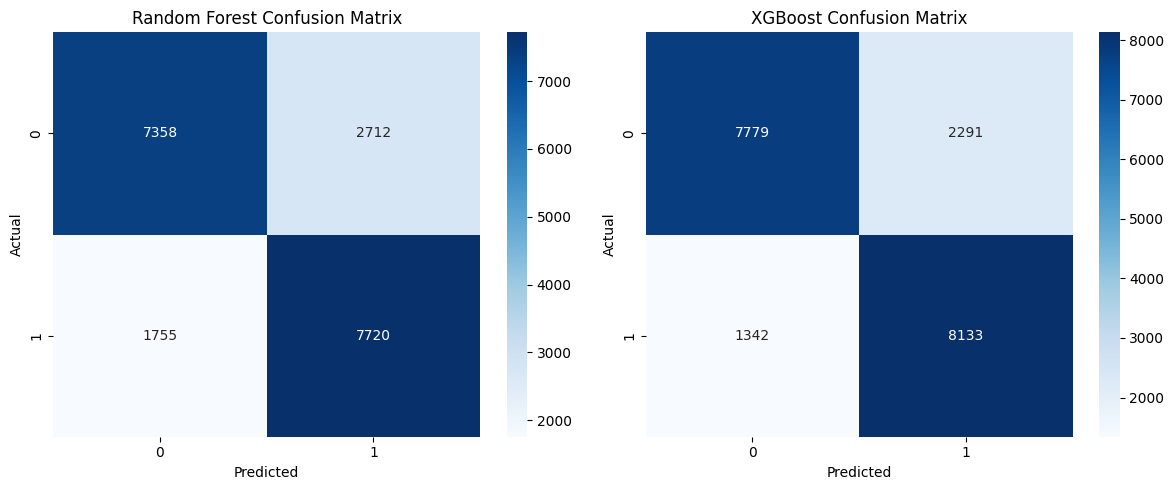

In [ ]:
# Create subplots for confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Random Forest Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# XGBoost confusion matrix
cm_xgb = confusion_matrix(y_test, xgb_pred)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('XGBoost Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

**Observations:**

Comparing the two models, XGBoost clearly outperforms Random Forest across all key metrics in the confusion matrices:

*   **Higher True Positives:** XGBoost correctly predicted **8,133** individuals as needing mental health treatment, compared to Random Forest’s **7,720**. This represents a significant improvement in detecting actual cases.

*   **Fewer False Negatives:** XGBoost reduced missed cases (people who need treatment but were predicted as not needing it) to just **1,342**, notably better than Random Forest’s **1,755**. In mental health screening, minimizing false negatives is especially crucial.

*   **Fewer False Positives:** XGBoost also generated fewer incorrect positive predictions **2,291** than Random Forest **2,712**, resulting in greater precision when identifying people who do not need treatment.

*   **Higher True Negatives:** XGBoost correctly identified **7,779** individuals as not needing treatment, compared to Random Forest’s **7,358**.

**Overall Impact:** XGBoost delivers a more accurate, balanced, and reliable performance. It excels at identifying those who need help while reducing both critical errors (missed cases) and unnecessary alarms, making it the superior model for this mental health treatment prediction task.

#### **9.3: ROC Curve and AUC Analysis**

Random Forest AUC: 0.8755671827550155
XGBoost AUC: 0.9302908086665111


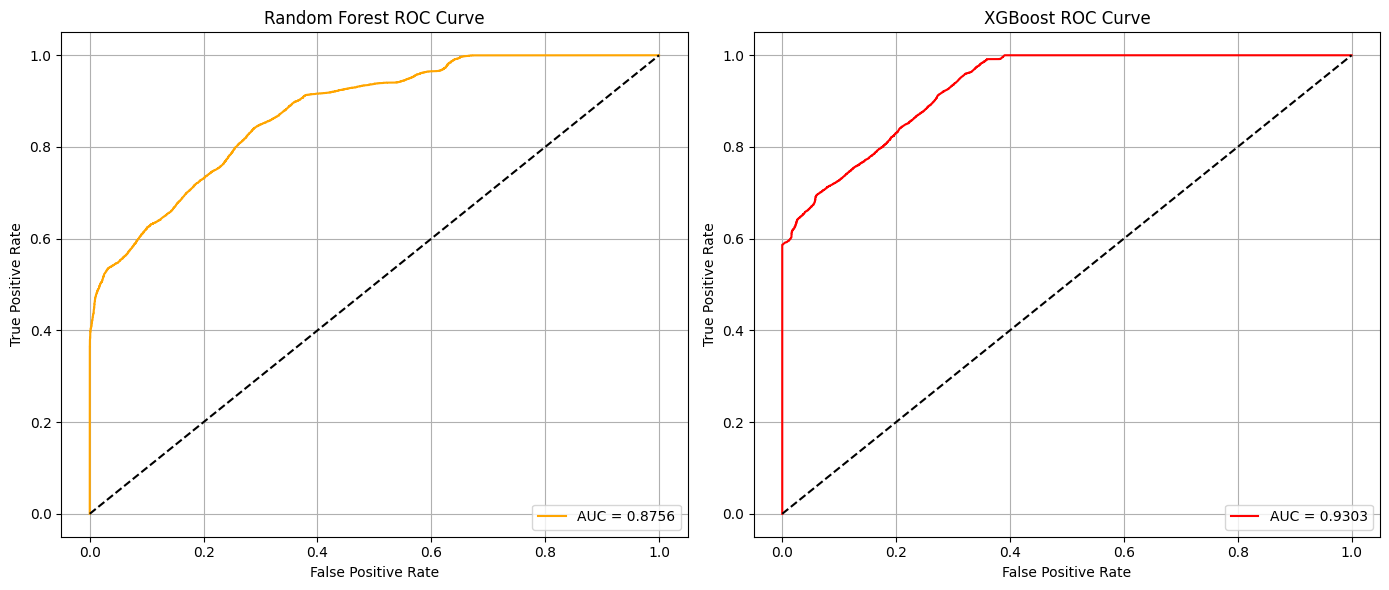

In [ ]:
# Get prediction probabilities
rf_probs = best_rf.predict_proba(X_test)[:, 1]
xgb_probs = best_xgb.predict_proba(X_test)[:, 1]

# Reciever Operating Characteristic Curve (ROC)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)

# AUC scores
auc_rf = auc(fpr_rf, tpr_rf)
auc_xgb = auc(fpr_xgb, tpr_xgb)

# Print AUC values
print("Random Forest AUC:", auc_rf)
print("XGBoost AUC:", auc_xgb)

# Plot ROC curves
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Random Forest ROC
axes[0].plot(fpr_rf, tpr_rf, label=f'AUC = {auc_rf:.4f}', color='orange')
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title('Random Forest ROC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# XGBoost ROC
axes[1].plot(fpr_xgb, tpr_xgb, label=f'AUC = {auc_xgb:.4f}', color='red')
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('XGBoost ROC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Observations:**

Comparing the ROC curves, XGBoost significantly outperforms Random Forest in terms of overall discriminative ability:

*   **XGBoost** achieves a strong **AUC of 0.9303**, indicating excellent model performance and strong ability to distinguish between individuals who need mental health treatment and those who do not.
*   **Random Forest** shows a respectable but lower **AUC of 0.8756**.

The XGBoost curve rises more sharply and stays consistently higher than Random Forest’s, reflecting better sensitivity and specificity across various thresholds. This confirms XGBoost as the superior model, offering higher predictive reliability for mental health treatment needs.

#### **9.4: Feature Importance Analysis**

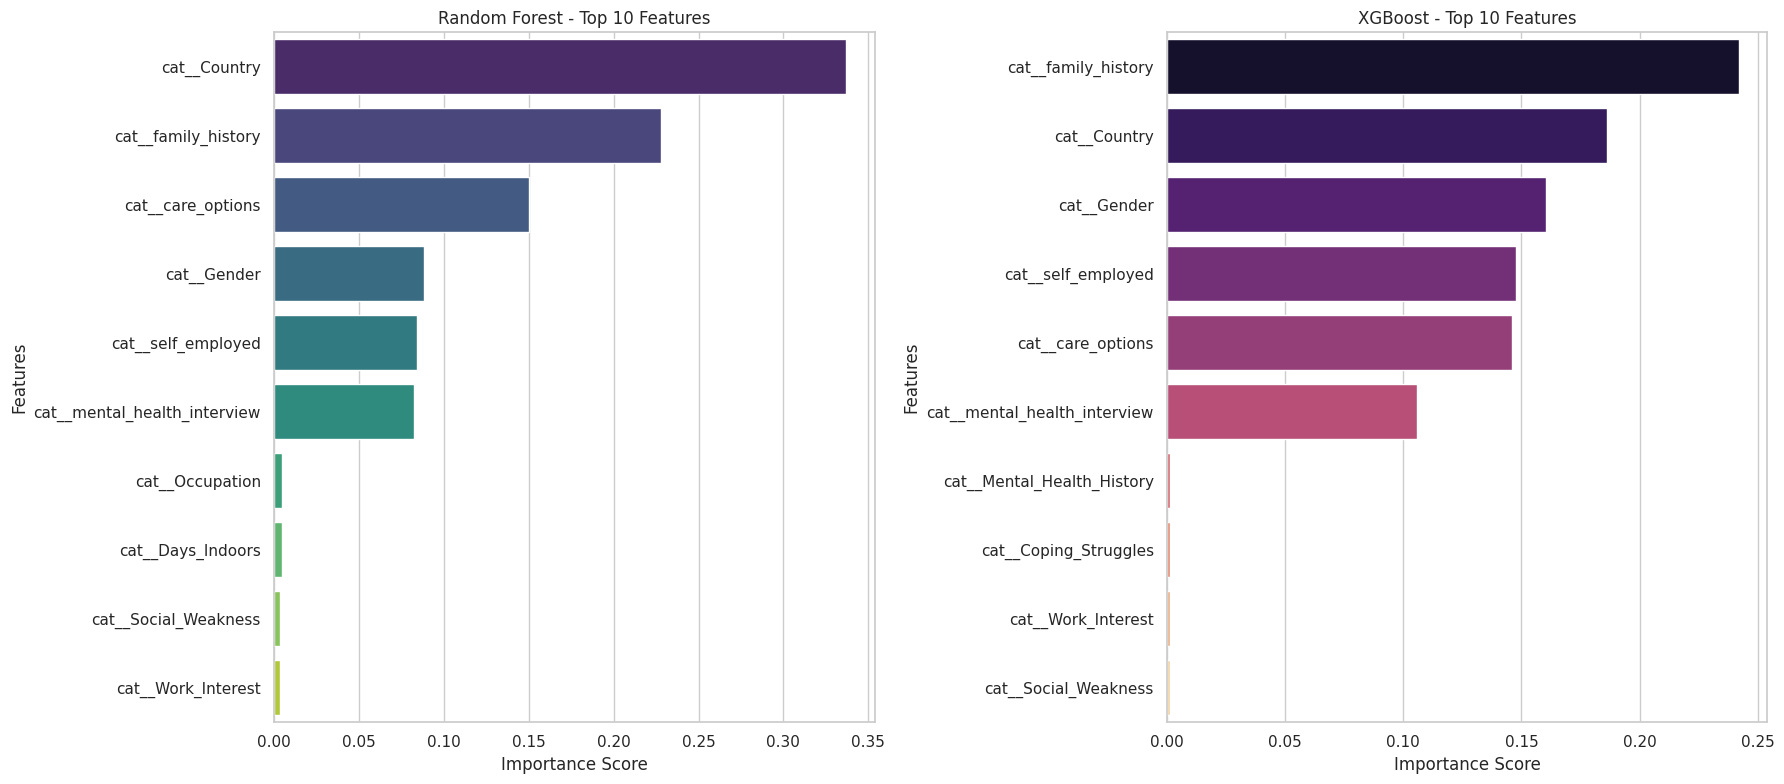

In [ ]:
# Set plot style
sns.set(style="whitegrid")

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Get feature names after preprocessing from the fitted best_rf model
feature_names = best_rf.named_steps['preprocessor'].get_feature_names_out()

# Random Forest feature importance
rf_importances = pd.Series(
    best_rf.named_steps['model'].feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

sns.barplot(
    x=rf_importances.values,
    y=rf_importances.index,
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Random Forest - Top 10 Features')
axes[0].set_xlabel('Importance Score')
axes[0].set_ylabel('Features')

# XGBoost feature importance
xgb_importances = pd.Series(
    best_xgb.named_steps['model'].feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

sns.barplot(
    x=xgb_importances.values,
    y=xgb_importances.index,
    ax=axes[1],
    palette='magma'
)
axes[1].set_title('XGBoost - Top 10 Features')
axes[1].set_xlabel('Importance Score')
axes[1].set_ylabel('Features')

plt.tight_layout()
plt.show()

**Key Insights from Feature Importance:**


*   Both models agree that **Country** and **Family History** are among the most influential factors in predicting mental health treatment needs.
*   **XGBoost** gives significantly higher importance to **Family History**, making it the dominant feature — suggesting it captures a stronger predictive signal for treatment needs.
*   **Random Forest** places the highest weight on **Country**, followed by Family History and Care Options.
*   Common important features across both models include: **Gender, Self Employed, Care Options, and Mental Health Interview.**
*   Less impactful features (such as Occupation, Days Indoors, Social Weakness, etc.) show very low importance in both models.


While there is good alignment between the models, XGBoost appears to focus more sharply on Family History as the key predictor, whereas Random Forest spreads importance more towards Country and Care Options. This explains why XGBoost delivered superior performance in earlier evaluations.


### **10: Cross-Validation**

In [ ]:
xcv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Random Forest cross-validation
cv_rf = cross_val_score(
    best_rf,
    X_train,
    y_train,
    cv=xcv,
    scoring='accuracy',
    n_jobs=-1
)

# XGBoost cross-validation using the best_xgb model
cv_xgb = cross_val_score(
    best_xgb,
    X_train,
    y_train,
    cv=xcv,
    scoring='accuracy',
    n_jobs=-1
)


# Cross-validation comparison
comparison_cv = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "CV Mean Accuracy": [cv_rf.mean(), cv_xgb.mean()],
    "CV Std Dev": [cv_rf.std(), cv_xgb.std()]
})

# Display results
display(comparison_cv)

,Model,CV Mean Accuracy,CV Std Dev
0,Random Forest,0.772442,0.002465
1,XGBoost,0.811968,0.001420


### **11: Best Model Selection**



In [ ]:
best_model_name = comparison_cv.loc[
    comparison_cv["CV Mean Accuracy"].idxmax(),
    "Model"
]

print("Best Model Selected (based on CV Mean Accuracy):", best_model_name)

Best Model Selected (based on CV Mean Accuracy): XGBoost


**Justification for Model Selection: XGBoost**

Based on a comprehensive evaluation across multiple key performance indicators, XGBoost is selected as the best model for this mental health prediction task due to:

*   **Superior Cross-Validation Accuracy:** Achieved a higher mean cross-validation accuracy, demonstrating better generalization capability compared to Random Forest.
*   **Higher Overall Accuracy:** Outperformed Random Forest in overall test set accuracy, indicating more correct predictions.
*   **Excellent ROC-AUC Score:** Exhibited a significantly higher ROC-AUC (0.93 vs 0.87 for Random Forest), highlighting its superior discriminative power in distinguishing between individuals who need treatment and those who don't.
*   **Enhanced Classification Stability (Confusion Matrix Analysis):** Crucially, XGBoost showed a remarkable reduction in false negatives (missed cases) and a higher number of true positives. This is vital in a mental health context, as minimizing false negatives ensures more individuals who require support are correctly identified. It also maintained low false positives, leading to more reliable predictions overall.
*   **Ability to Capture Complex Patterns:** As an ensemble method, XGBoost effectively handles non-linear relationships and intricate data patterns, which are often present in behavioral and psychological datasets.

### **12: Model Persistence (Saving the Model)**

In [ ]:
# Select best model
final_model = rf_pipeline if best_model_name == "Random Forest" else best_xgb
# Encode full target
y_encoded = le_target.transform(y.astype(str))

# Train final model on full dataset
final_model.fit(X, y_encoded)
print("Final model trained on full dataset.")

# Save full pipeline (production-ready)
joblib.dump({
    "model": final_model,
    "label_encoder": le_target,
    "features": X.columns.tolist()
}, "best_mental_health_model.joblib")

print("Model saved in production-ready format.")

Final model trained on full dataset.
Model saved in production-ready format.


### **13: Insights and Discussion**

#### **13.1: Final Insights**

*   Dataset is well-balanced.
*   Behavioral and psychological factors (family history, mental health history, stress, mood swings) are strong indicators.
*   XGBoost outperforms Random Forest, especially in recall, for identifying at-risk individuals.

#### **13.2: Model Limitations and Ethical Considerations**

**Bias and Fairness:** Self-reported data risk response bias. Demographic representation needs examination; model performance may degrade for underrepresented groups. Not for clinical diagnosis.

**Generalizability:** Model performance on diverse populations is uncertain without external validation. Its generalizability to broader real-world mental health scenarios is not guaranteed.

**Ethical Limitations:** Misclassifying (false negatives/positives) carries significant risks. Model doesn't account for dynamic mental health states. Use as a supportive tool with human expertise.

**Survey Reliability:** Reliability depends on consistent and accurate data collection. Limited survey questions may not fully capture mental health nuances.

**Overfitting Risk:** Complex models like XGBoost, even with CV, risk capturing noise. Fine-tuning might cause performance drops on new, unseen data.

### **14: Conclusion**

This project successfully demonstrates that machine learning can predict mental health treatment needs. The XGBoost model performed optimally, highlighting family_history, care_options, and various behavioral patterns as key indicators. This model serves as a valuable tool for early detection and intervention, designed to complement, not replace, professional clinical assessment.